In [13]:
import torch
import matplotlib.pyplot as plt
import numpy as np
import torch.nn as nn

In [14]:
IC_coefficients = torch.load('./results/wave_equation/ic_coeff_20_3.pt')
IC_neuman_coeffs = torch.load('./results/wave_equation/ic_neum_coeff_20_3.pt')

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_73436\2491872304.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  IC_coefficients = torch.load('./results/wave_equation/ic

In [15]:

class bsplines2D(nn.Module):

    def __init__(self, n_basis, degree, device):
        super().__init__()
        self.degree = degree
        self.n_basis = n_basis
        self.n_knots = n_basis + degree + 1
        # Uniform clamped bsplines
        knot_vector = torch.linspace(0, 1, self.n_knots - 2 * degree)
        self.knot_vector = torch.cat((
                torch.full((degree,), knot_vector[0]),
                knot_vector,
                torch.full((degree,), knot_vector[-1])
            ))
        
        # Same knot vector in every direction
        self.knot_x = self.knot_vector.clone()
        self.knot_t = self.knot_vector.clone()

        # 2D interior domain trainable coefficients (needs first to require grad and then to send to device.)
        self.coeffs_trainable = torch.zeros(n_basis-2, n_basis-2,device=device, requires_grad=True)

        # Define the coeff based on the Dirichlet boundary conditions.
        # IC at t=0
        self.coeffs_row_0=IC_coefficients
        self.coeffs_row_1=IC_neuman_coeffs
        
        # BC 
        self.coeffs_rl = torch.tensor([0.0])
        # self.coeffs_trainable.requires_grad_()
        # 2D input
        # self.x = x
        
        
        # Bsplines for the two dimensions
        ################Changes#################
        # self.D = torch.rand(1)
        # self.D.requires_grad_()
        self.raw_c = nn.Parameter(torch.tensor([0], dtype=torch.float32))  # initial guess
        self.softplus = nn.Softplus()
        ################Changes#################

        
    def bspline_basis(self,i, p, x, knots):
        if p == 0:

            #######Change#############
            #In degree 2 when I put = it gets bad
            return ((x >= knots[i]) & (x <= knots[i+1])).float()
            # return ((x >= knots[i]) & (x < knots[i+1])).float()
            #######Change#############
        
        else:
            denom1 = knots[i+p] - knots[i]
            denom2 = knots[i+p+1] - knots[i+1]

            term1 = 0.0
            if denom1 > 0:
                term1 = (x - knots[i]) / denom1 * self.bspline_basis(i, p-1, x, knots)

            term2 = 0.0
            if denom2 > 0:
                term2 = (knots[i+p+1] - x) / denom2 * self.bspline_basis(i+1, p-1, x, knots)

            return term1 + term2

    def forward(self,x, device):

        self.B_x = torch.stack([self.bspline_basis(i, self.degree, x[:,0], self.knot_x ) for i in range(self.n_basis)])
        self.B_t = torch.stack([self.bspline_basis(j, self.degree, x[:,1], self.knot_t) for j in range(self.n_basis)])



        y = torch.zeros(x.shape[0], device=device)
        # Adding the internal domain bsplines
        for i in range(2,self.n_basis):
            for j in range(1,self.n_basis-1):
                y += self.coeffs_trainable[i-2, j-1] * self.B_t[i]*self.B_x[j]

        # Adding the Dirichlet IC  
        for i in range(self.n_basis):
            y += self.coeffs_row_0[i]*self.B_t[0]*self.B_x[i]

        # Adding the Neumann IC in the second row  
        for i in range(self.n_basis):
            y += self.coeffs_row_1[i]*self.B_t[1]*self.B_x[i]

        #Adding BC to the left side
        for i in range(2,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[0]

        #Adding BC to the left side
        for i in range(2,self.n_basis):

            y+=self.coeffs_rl*self.B_t[i]*self.B_x[self.n_basis-1]


        return y
    
    def c(self):
        return self.softplus(self.raw_c)
    
    # send every attribute to device
    def to(self, device):
        for attr, value in self.__dict__.items():
            if isinstance(value, torch.Tensor):
                setattr(self, attr, value.to(device))
   


In [16]:
torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [23]:
device

device(type='cuda')

In [17]:
torch.manual_seed(42)

model = bsplines2D(20,3, device)


In [18]:
model.to(device)

In [19]:
colloc_points = 5000

# Reproducable input points
torch.manual_seed(42)

X = torch.rand(colloc_points,2)
#########Change###########
u_exact = torch.sin(torch.pi * X[:,0]) * torch.cos(torch.pi*X[:,1])
u_exact = u_exact.to(device)
noise = torch.normal(mean=0.0, std=0.05, size=u_exact.shape)
noise = noise.to(device)
u_noisy = u_exact + noise
#########Change###########
X = X.to(device)
X.requires_grad_(True)


tensor([[0.8823, 0.9150],
        [0.3829, 0.9593],
        [0.3904, 0.6009],
        ...,
        [0.9278, 0.5794],
        [0.8308, 0.2181],
        [0.9120, 0.4111]], device='cuda:0', requires_grad=True)

In [20]:
epochs = 1000
learning_rate=1e-3

###########Changes#################
optimizer = torch.optim.Adam([model.coeffs_trainable, model.raw_c], lr=learning_rate)
###########Changes#################



In [21]:
loss_vec = []

In [22]:
epochs = 10000

for epoch in range(epochs):

    optimizer.zero_grad()

    u = model.forward(X, device)
    grads = torch.autograd.grad(u, X, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_x = grads[:, 0]
    u_t = grads[:, 1]
    u_xx = torch.autograd.grad(u_x, X, torch.ones_like(u_x), create_graph=True)[0][:, 0]
    u_tt = torch.autograd.grad(u_t, X, torch.ones_like(u_x), create_graph=True)[0][:, 1]

    c = model.c().to(device)

    # Residual loss
    res = u_tt -c*u_xx
    
    loss_pde = torch.mean(res**2)
    loss_data = torch.mean((u - u_exact)**2) 
    loss = loss_pde + 10*loss_data

    loss.backward()
    optimizer.step()
    
    loss_vec.append(loss.item())
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        c_est = c.item()
        print(f"Epoch {epoch:5d} | Loss: {loss.item():} | D: {c_est:}")

Epoch     4 | Loss: 7318.1396484375 | D: 0.6951493620872498
Epoch     9 | Loss: 7207.29736328125 | D: 0.6976595520973206
Epoch    14 | Loss: 7098.12109375 | D: 0.7001799941062927
Epoch    19 | Loss: 6990.6171875 | D: 0.7027130126953125
Epoch    24 | Loss: 6884.80224609375 | D: 0.7052610516548157


KeyboardInterrupt: 

In [38]:
loss_pde

tensor(7.6042e-05, device='cuda:0', grad_fn=<MeanBackward0>)

In [12]:
#Save loss
loss_vec_npy = np.array(loss_vec)
np.save('./results/wave_inverse/bsplines_loss1.npy', loss_vec_npy )

#Save model trainable parameters
params = { 'coeffs_trainable': model.coeffs_trainable, 'D_trainable': model.raw_c }
torch.save(params, './results/wave_inverse/model_bsplines1.pth')

In [36]:
print(model.c().item())

1.0079387426376343


In [41]:
# Load model trainable parameters
model_s = bsplines2D(20,3,device)
loaded_params = torch.load('./results/wave_inverse/model_bsplines_noise.pth')
model_s.coeffs_trainable = loaded_params['coeffs_trainable']
model_s.raw_c = loaded_params['D_trainable']

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_35348\322735783.py:3: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  loaded_params = torch.load('./results/wave_inverse/model_

In [43]:
model_s.to(device)

In [44]:
model_s.c().item()

0.9996996521949768

In [12]:
# Load loss
loss_bsplines_s = np.load('./results/wave_inverse/bsplines_loss_noise.npy')
loss_pinn = np.load('./results/wave_inverse/pinn_loss.npy')

In [36]:
loss_bsplines_s[-1]
loss_pinn.shape

(130000,)

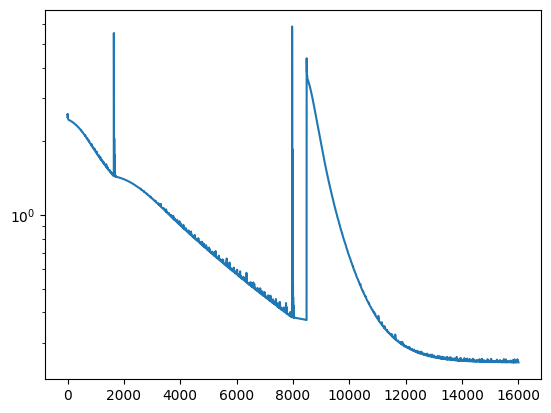

In [29]:
plt.plot(loss_bsplines_s) 
plt.yscale('log')

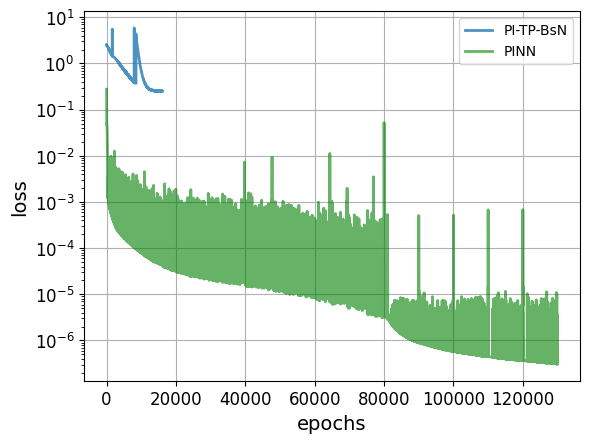

In [13]:

x_a = np.arange(len(loss_bsplines_s))
x_b = np.arange(len(loss_pinn))
plt.plot(x_a, loss_bsplines_s, label='PI-TP-BsN', alpha=0.8,linewidth=2)
plt.plot(x_b, loss_pinn, label='PINN', alpha=0.6, color='green',linewidth=2)
plt.legend()
plt.yscale('log')
# plt.title("Losses",fontsize=14)
plt.xlabel("epochs",fontsize=14)
plt.ylabel("loss",fontsize=14)
plt.tick_params(axis='both', labelsize=12)
plt.grid(True)

# plt.savefig('./results/wave_inverse/loss_inv_wave.pdf', dpi=300)
plt.show()

C:\Users\Polydoras\AppData\Local\Temp\ipykernel_35348\4265961430.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  XY_torch = torch.tensor(XY, dtype=torch.float32)


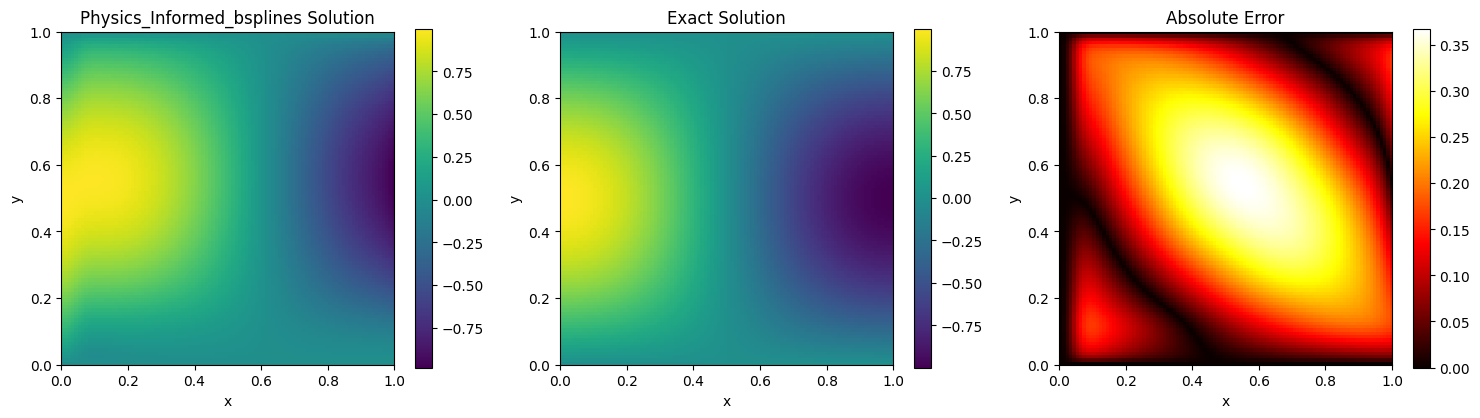

In [45]:
# 🔍 Test evaluate on a grid
x = y = torch.linspace(0, 1, 100)
Xg, Tg = torch.meshgrid(x, y)
Xg, Tg = Xg.to(device), Tg.to(device)
XY = torch.vstack([Xg.ravel(), Tg.ravel()]).T
XY_torch = torch.tensor(XY, dtype=torch.float32)
XY_torch = XY_torch.to(device)


# Prediction
with torch.no_grad():
    u_pred = model_s.forward(XY_torch, device).reshape(Xg.shape)

# ✅ Exact solution
u_exac = torch.sin(torch.pi * Xg) * torch.cos(torch.pi*Tg)


fig, axs = plt.subplots(1, 3, figsize=(15, 4))
# PINN solution
im0 = axs[0].imshow(u_pred.cpu(), extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[0].set_title("Physics_Informed_bsplines Solution")
fig.colorbar(im0, ax=axs[0])

# Exact solution
im1 = axs[1].imshow(u_exac.cpu(), extent=[0,1,0,1], origin='lower', cmap='viridis')
axs[1].set_title("Exact Solution")
fig.colorbar(im1, ax=axs[1])

# Absolute error
error = torch.abs(u_pred - u_exac)
im2 = axs[2].imshow(error.cpu(), extent=[0,1,0,1], origin='lower', cmap='hot')
axs[2].set_title("Absolute Error")
fig.colorbar(im2, ax=axs[2])

for ax in axs:
    ax.set_xlabel("x")
    ax.set_ylabel("y")

plt.tight_layout()
plt.show()

Table 7 and 8 RE but only for the Bsplines, for Pinns its in wave_inverse.ipynb

In [46]:
re=np.sqrt((model_s.c().item() - 1)**2)/np.sqrt(1**2)
re

0.00030034780502319336

In [16]:
u_exact.shape

torch.Size([5000])

In [49]:
re = torch.sqrt(torch.sum((u_pred - u_exac)**2))/torch.sqrt(torch.sum(u_exac**2))
re.item()

0.392281711101532

In [22]:
print(re.item())

0.392281711101532
